In [1]:


import json, math, warnings

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'models' / 'src'))
from common import paths, plots
from common.data import read_csv, show_dataset
from common.plots import (SUPERFICIE, TINTA, TINTA_2, PREDITO, enfeitar, plot_time_series)

plots.aplicar_estilo()



SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
NL = chr(10)   # evita barra invertida no fonte; usado nos relatorios


DATA_DIR = paths.RAW

print(f"dados em {DATA_DIR}")
print(f"semente: {SEED}")

dados em /home/scorel/Documents/knob-senses/data/raw
semente: 42


In [2]:
ARQUIVOS = (
    sorted(DATA_DIR.rglob("ifpee*.csv"))
)

print(f"{len(ARQUIVOS)} arquivos" + NL)

partes = []
for p in ARQUIVOS:
    df = read_csv(p)
    df['station'] = p.stem.split('_')[0]
    partes.append(df)
    print(f"  {p.parent.name:10} {p.stem:16} {len(df):7} linhas  {len(df.columns):2} colunas")

raw: pd.DataFrame = pd.concat(partes, ignore_index=True)

9 arquivos

  raw        ifpee1_2021        45872 linhas  18 colunas
  raw        ifpee1_2022        43750 linhas  18 colunas
  raw        ifpee1_2023        46380 linhas  18 colunas
  raw        ifpee1_2024        46514 linhas  19 colunas
  raw        ifpee1_2025        44969 linhas  19 colunas
  raw        ifpee2_2024        46514 linhas  19 colunas
  raw        ifpee2_2025        44969 linhas  19 colunas
  raw        ifpee3_2024        46514 linhas  19 colunas
  raw        ifpee3_2025        44969 linhas  19 colunas


In [3]:

# remover colunas "mortas"
REMOVE_COLS = {"ano", 'velocidade_vento', 'condicao' }
raw = raw.drop(columns=[c for c in REMOVE_COLS if c in raw.columns])

df = show_dataset(
  raw
    .copy()
    .dropna(subset=['PCA'])
    .reset_index(drop=True)
) 


pool: 410375 linhas, 17 colunas

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
PCA    9607


In [4]:
# Cleanup dataset
outages = (raw.PCA == 0) & (raw.ghit > 50)
clipping = (raw.PCA >= 1.95)
low_irradiance = (raw.ghit < 5)
high_temperature = (raw.temperatura_ambiente >= 50)

df = raw[~outages & ~clipping & ~low_irradiance & ~high_temperature].copy()

df = show_dataset(df.reset_index(drop=True))


pool: 396524 linhas, 17 colunas

nulos por coluna (so as que tem):
PCA    76

colunas com zero:
PCA    1057


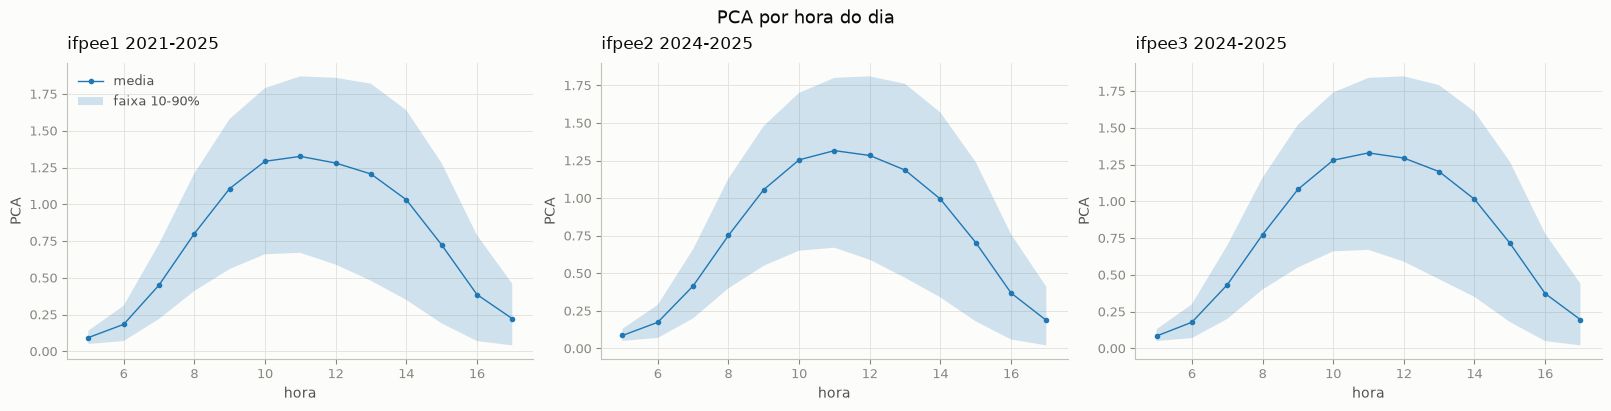

In [5]:
d2 = df.copy()

d2["hora"] = d2.datetime.dt.hour

# 1) PCA por hora do dia, uma estacao por painel (media + faixa 10-90%)
lines = (len(d2.station.unique()) / 2).__round__()
fig, axs = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
for ax, (nome, d) in zip(axs.flat, d2.groupby("station")):
    g = d.groupby("hora")["PCA"]
    ax.plot(g.mean().index, g.mean().values, marker=".", lw=1, label="media")
    ax.fill_between(g.mean().index, g.quantile(0.1).values, g.quantile(0.9).values,
                    alpha=0.2, label="faixa 10-90%")
    enfeitar(ax, f"{nome} {d.datetime.dt.year.min()}-{d.datetime.dt.year.max()}", "hora", "PCA")
axs.flat[0].legend(frameon=False, fontsize=9, labelcolor=TINTA_2)
_ = fig.suptitle("PCA por hora do dia", color=TINTA, fontsize=13)

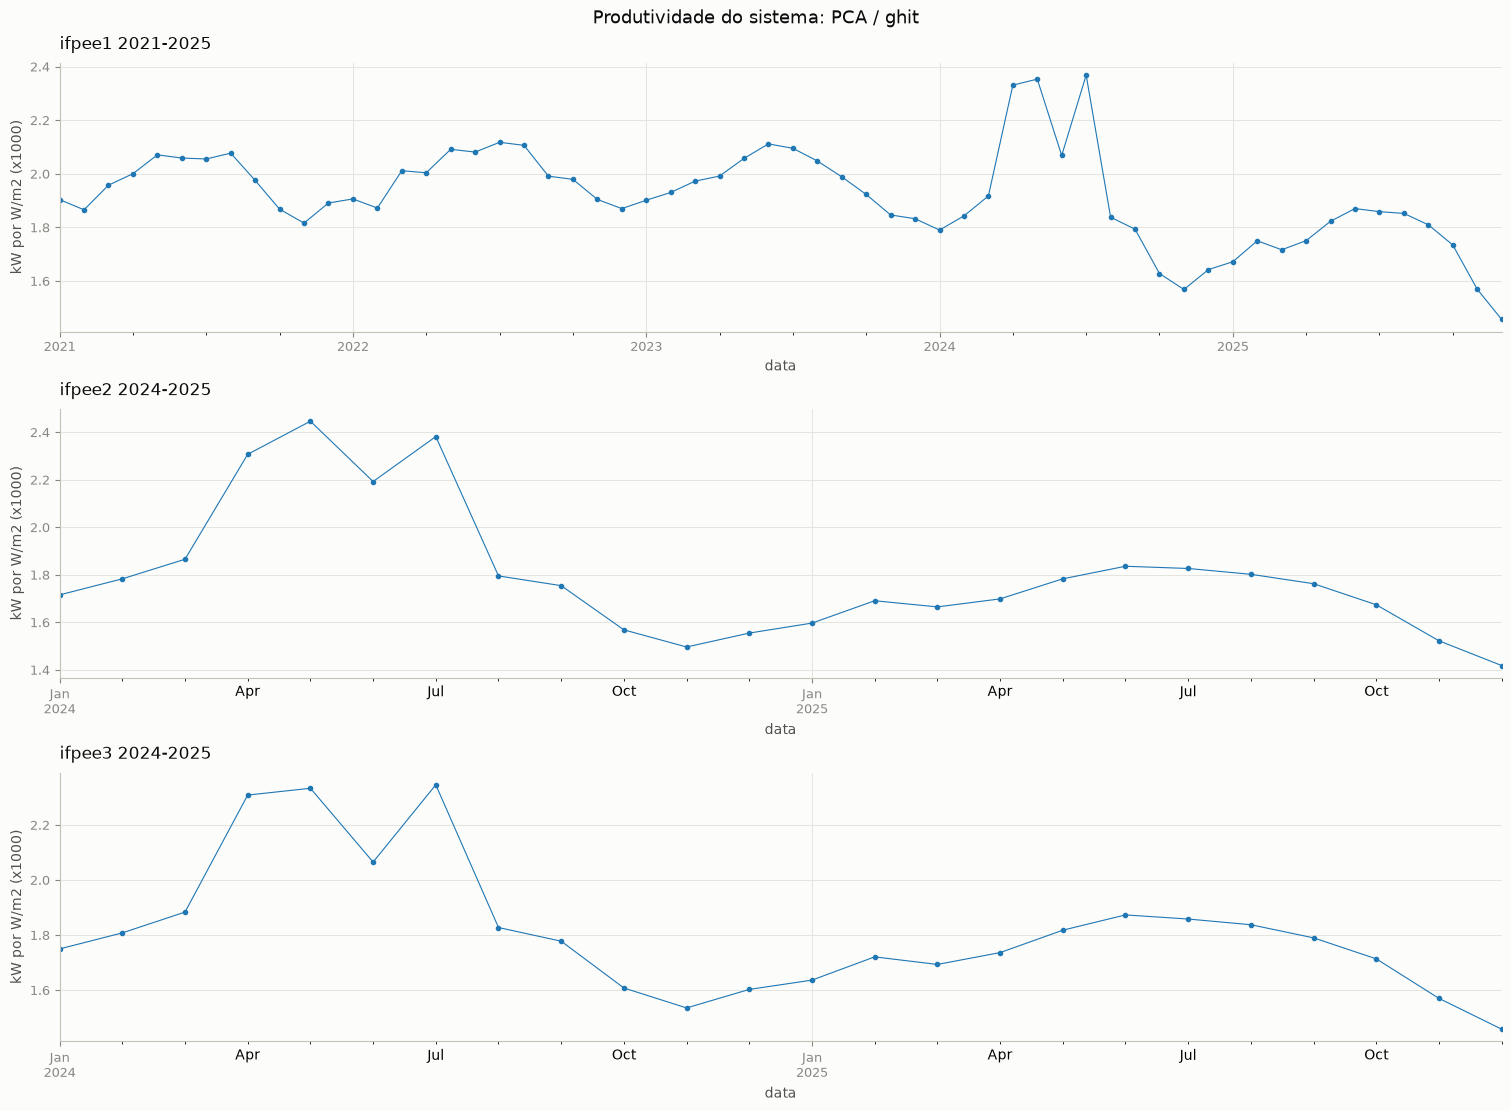

In [6]:
# 4) Eficiencia do sistema PCA / ghit (media diaria, x1000), uma estacao por painel.
# A razao cancela a sazonalidade de sol; o que sobra e' o estado do sistema.
fig, axs = plt.subplots(3, 1, figsize=(15, 11), constrained_layout=True)
for ax, (nome, d) in zip(axs.flat, d2.groupby("station")):
    dd = d[(d.PCA != 0) & (d.ghit > 0)]
    dd['ef'] = dd.PCA / dd.ghit
    dd = dd.groupby(dd["datetime"].dt.to_period("M")).agg({
        'ef': 'mean',
        'datetime': 'first'
    })
    ef = dd.ef
    (ef * 1000).plot(ax=ax, marker=".", lw=0.8)
    enfeitar(ax, f"{nome} {dd.datetime.dt.year.min()}-{dd.datetime.dt.year.max()}", "data", "kW por W/m2 (x1000)")
fig.suptitle("Produtividade do sistema: PCA / ghit", color=TINTA, fontsize=13)

del d2

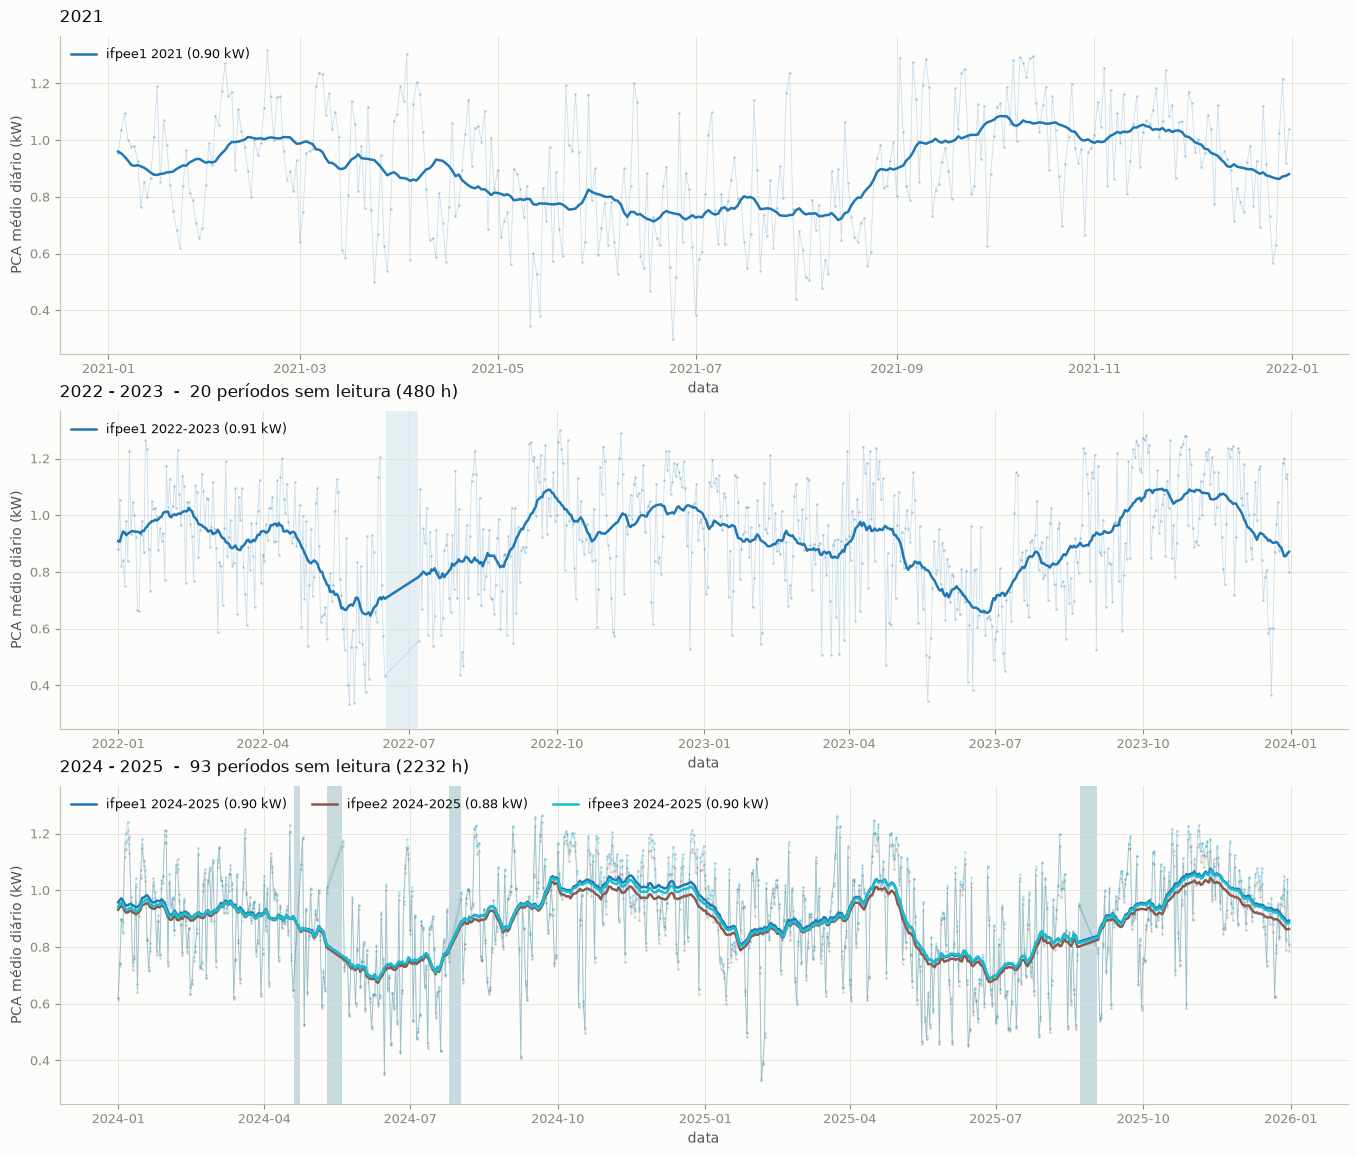

In [7]:
plot_time_series(df.reset_index(), janela='30d', freq="1D")


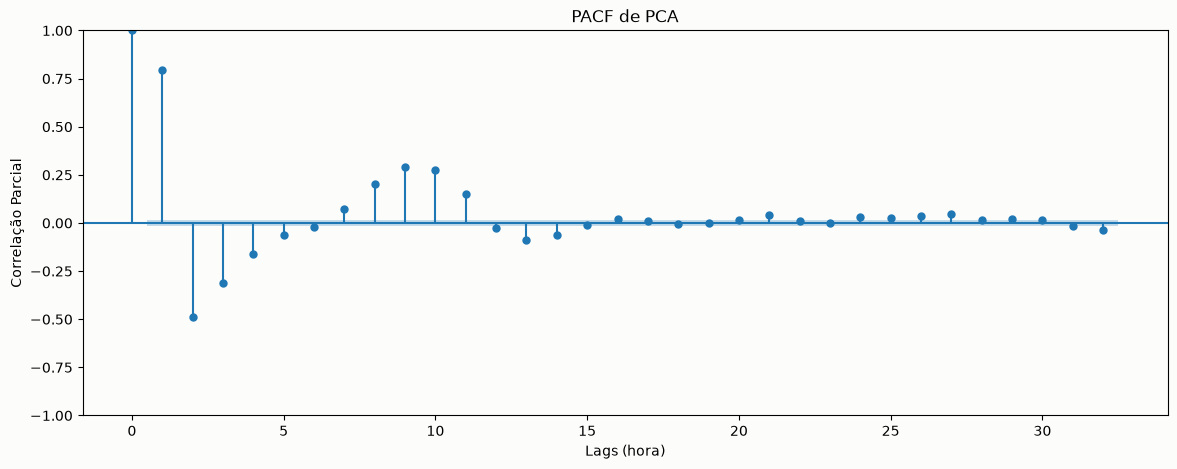

In [8]:
from statsmodels.graphics.tsaplots import plot_pacf

df_a = df.copy()  # remove 2024, que tem perda de dados
PCA = df_a.groupby([pd.Grouper(key='datetime', freq='1h')]).PCA.mean().dropna()


fig, ax = plt.subplots(figsize=(14, 5))
plot_pacf(PCA, ax=ax, lags=32, method="ywm", title="PACF de PCA")


# 3. Exibindo o gráfico
ax.set_xlabel("Lags (hora)")
ax.set_ylabel("Correlação Parcial")

plt.show()

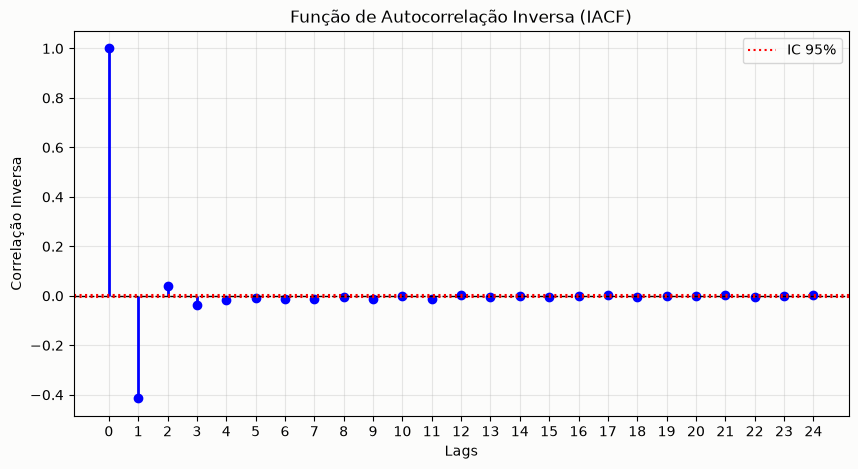

In [9]:
from statsmodels.regression.linear_model import yule_walker

def plot_iacf(series, lags=20):
    """
    Calcula e plota a Função de Autocorrelação Inversa (IACF)
    baseada na aproximação por um modelo autorregressivo de alta ordem.
    """
    # Remove valores nulos caso existam na série do Pandas
    series = series.dropna()
    n = len(series)
    
    # 1. Ajusta um modelo AR de alta ordem (Yule-Walker)
    # Geralmente usa-se a ordem sugerida pela metade das observações ou um limite prático
    ar_order = min(lags * 2, n // 3)
    ar_coefs, _ = yule_walker(series, order=ar_order, demean=True)
    
    # 2. Convoluciona os coeficientes AR com eles mesmos para obter a IACF aproximada
    # Adiciona 1 no início para representar o lag 0
    ar_operator = np.r_[1, -ar_coefs]
    iacf_raw = np.correlate(ar_operator, ar_operator, mode='full')
    
    # Pega apenas a metade positiva (lags de 0 em diante)
    iacf = iacf_raw[len(iacf_raw)//2 : len(iacf_raw)//2 + lags + 1]
    
    # Normaliza para que o lag 0 seja igual a 1
    iacf = iacf / iacf[0]

    # Remove lags muito baixos para evitar ruído visual (opcional)
    # iacf = np.where(np.abs(iacf) < 0.1, 0, iacf)
    
    # 3. Monta o gráfico no estilo clássico do statsmodels
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Plota as barras verticais para os lags de 1 até o limite definido
    x_lags = np.arange(len(iacf))
    ax.vlines(x_lags, 0, iacf, colors='b', lw=2)
    ax.plot(x_lags, iacf, 'bo')
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    
    # Limites de significância estatística aproximados (IC de 95%)
    conf_level = 1.96 / np.sqrt(n)
    ax.axhline(conf_level, color='red', linestyle=':', label='IC 95%')
    ax.axhline(-conf_level, color='red', linestyle=':')
    
    ax.set_title("Função de Autocorrelação Inversa (IACF)")
    ax.set_xlabel("Lags")
    ax.set_ylabel("Correlação Inversa")
    ax.set_xticks(x_lags)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_iacf(df.PCA, lags=24)

In [10]:
import pandas as pd
def downsample(df: pd.DataFrame, interval: str):
    d = df.copy() 
    invalid = (
        (d.PCA == 0) | (d.ghit < 10) | 
        (d.temperatura_ambiente > 50) | 
        (d.PCA > 1.95)
    )
    d.drop(d[invalid].index, inplace=True)
    d = d.reset_index(drop=True)
    d = d.groupby(['datetime']).agg({'PCA': 'mean'})
    d = d[d.isna().sum(axis=1) == 0].reset_index()
    
    a = d.groupby(pd.Grouper(key="datetime", freq=interval))
    d = a.filter(lambda group: group["PCA"].ne(0).all())

    return d.groupby(pd.Grouper(key="datetime", freq=interval)).agg({'PCA': 'sum'})


/tmp/ipykernel_1987436/3050925846.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  d.drop(d[invalid].index, inplace=True)


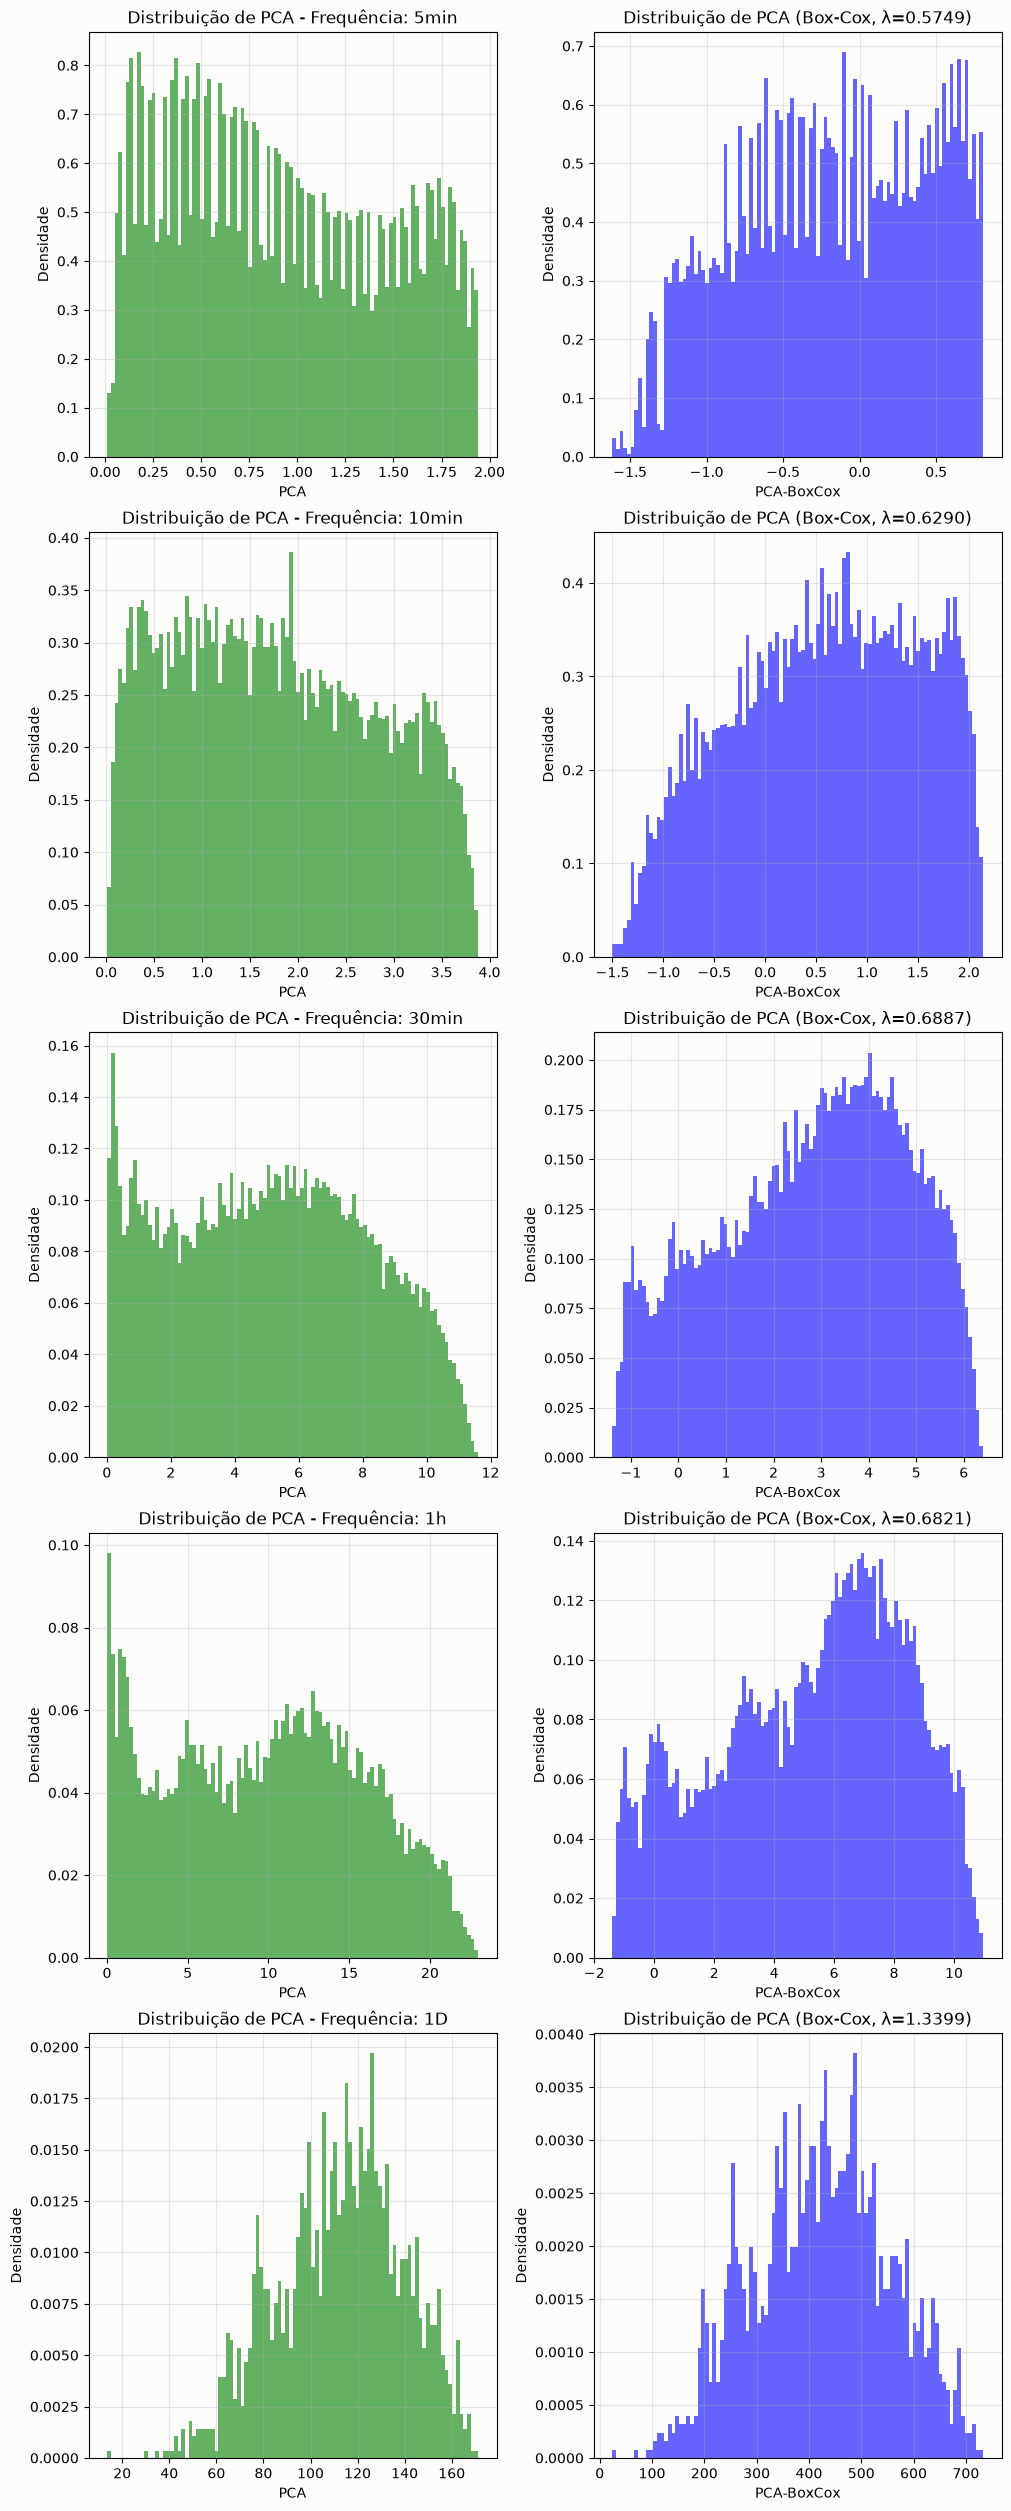

In [ ]:
from scipy import stats

intervals = ('5min', '10min', '30min', '1h', '1D')
lines = len(intervals)
fig, ax = plt.subplots(figsize=(10, 5 * lines), ncols=2, nrows=lines, constrained_layout=True)


frames = (downsample(df, interval) for interval in intervals)

for freq, d2, ax in zip(intervals, frames, ax):
    d2 = d2[d2.PCA > 0].reset_index(drop=True)
    d2['PCA-BoxCox'], lmbda = stats.boxcox(d2['PCA'])
    
    ax[0].hist(d2['PCA'], bins=100, density=True, alpha=0.6, color='g')
    ax[0].set_title(f"Distribuição de PCA - Frequência: {freq}")
    ax[0].set_xlabel("PCA")
    ax[0].set_ylabel("Densidade")
    ax[0].grid(alpha=0.3)

    ax[1].hist(d2['PCA-BoxCox'], bins=100, density=True, alpha=0.6, color='b')
    ax[1].set_title(f"Distribuição de PCA (Box-Cox, λ={lmbda:.4f})")
    ax[1].set_xlabel("PCA-BoxCox")
    ax[1].set_ylabel("Densidade")
    ax[1].grid(alpha=0.3)
  
fig.show()

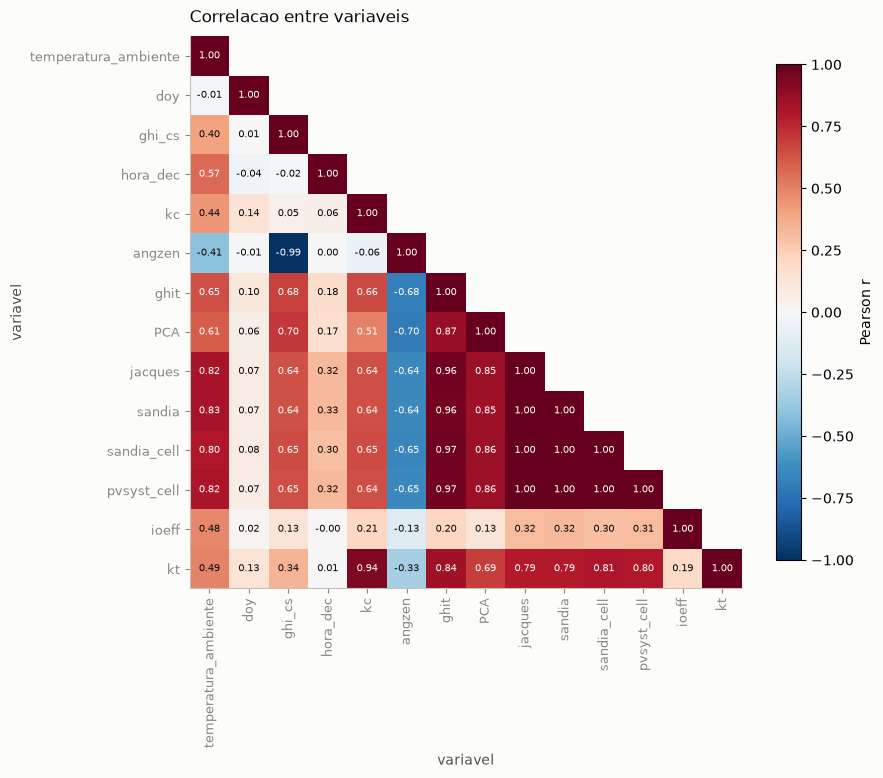

In [12]:
# Correlation matrix
corr_matrix = df.select_dtypes(include=[np.number]).corr()
# heatmap da matriz de correlacao (so o triangulo inferior; a matriz e' simetrica)
n = len(corr_matrix)
mask = np.triu(np.ones((n, n), dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr_matrix.mask(mask).to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(n), corr_matrix.columns, rotation=90)
ax.set_yticks(range(n), corr_matrix.index)
ax.set_aspect("equal")
enfeitar(ax, "Correlacao entre variaveis", "variavel", "variavel")
ax.grid(False)

# anota o valor de Pearson dentro de cada celula
for r in range(n):
  for c in range(n):
    if c <= r:
      v = corr_matrix.iloc[r, c]
      ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
          color=SUPERFICIE if abs(v) > 0.5 else TINTA)

plt.colorbar(im, ax=ax, label="Pearson r", shrink=0.8)
plt.tight_layout()
plt.show()

In [13]:

numeric_cols = df.select_dtypes(include="number").columns

summary_stats = (
  df.groupby("station")[numeric_cols]
    .agg(["min", "max", "mean", "std"])
)

summary_stats

temperatura_ambiente                              doy                                  ghi_cs                                       hora_dec                                       kc  \
                         min     max       mean       std min  max        mean         std        min          max        mean         std       min        max       mean       std      min   
station                                                                                                                                                                                         
ifpee1                 6.338  40.786  27.373295  4.136275   1  366  184.455338  107.671937  79.332931  1066.308609  657.586244  285.021967  5.779167  17.116667  11.462101  3.090805  0.00851   
ifpee2                 6.338  40.786  27.685941  4.241224   1  366  184.081337  108.714716  79.332931  1066.308609  661.887964  285.683165  5.783333  17.116667  11.462832  3.073207  0.00851   
ifpee3                 6.338  40.786  27.670263  4.241425   1  366  184.234172  108.707216  79.332931  1066.308609  660.533351  285.588584  5.783333  17.116667  11.458832  3.079029  0.00851   

                                         angzen                                       ghit                                       PCA                              jacques                        \
              max      mean       std       min        max       mean        std       min          max        mean         std  min   max      mean       std        min        max       mean   
station                                                                                                                                                                                           
ifpee1   8.761781  0.764439  0.337045  0.159979  79.999981  44.610019  20.050915  5.015856  1583.257158  508.019517  329.705064  0.0  1.94  0.905205  0.548285  11.031228  75.964472  40.828021   
ifpee2   8.761781  0.808337  0.348397  0.134047  79.999951  44.266208  20.168296  5.016667  1583.257158  543.681134  350.573816  0.0  1.94  0.883776  0.537259  11.031228  75.964472  42.240430   
ifpee3   8.761781  0.807216  0.348311  0.314131  79.999951  44.373672  20.140659  5.016667  1583.257158  541.362220  349.149782  0.0  1.94  0.897690  0.547082  11.031228  75.964472  42.162673   

                       sandia                                  sandia_cell                                  pvsyst_cell                                        ioeff                            \
               std        min        max       mean        std         min        max       mean        std         min       max       mean        std          min          max         mean   
station                                                                                                                                                                                          
ifpee1   11.985091  10.894606  74.730641  40.414789  11.764884   12.319189  87.596033  44.528404  14.363806   11.234698  77.80201  41.562806  12.294651  1321.019638  1411.180883  1367.814682   
ifpee2   12.545487  10.894606  74.730641  41.816736  12.281782   12.319189  87.596033  46.234618  15.048266   11.234698  77.80201  42.871517  12.938807  1321.019638  1411.180883  1368.433912   
ifpee3   12.505867  10.894606  74.730641  41.740786  12.243315   12.319189  87.596033  46.139825  14.997838   11.234698  77.80201  42.791070  12.897471  1321.019638  1411.180883  1368.411101   

                          kt                                
               std       min       max      mean       std  
station                                                     
ifpee1   31.702121  0.005853  4.457725  0.524413  0.237640  
ifpee2   31.910722  0.005853  4.457725  0.556146  0.248361  
ifpee3   31.935951  0.005853  4.457725  0.555029  0.247990